# Fatores associados à gravidade dos acidentes em rodovias federais brasileiras (2021–2025)

**Disciplina:** Python para Ciência de Dados  
**Atividade:** Atividade Prática Supervisionada (APS)  
**Professor:** Paulo C. Marques F.  
**Integrantes:** Camille Souza, Elora Rocha, Gabriela Afif e Maria Luiza Sevilha

---

## 1. Introdução e relevância

Os acidentes de trânsito são um problema de segurança pública, saúde e infraestrutura. Além das mortes e lesões, geram custos hospitalares, perdas de produtividade, danos materiais e impactos sobre a circulação de pessoas e mercadorias. Nas rodovias federais, o tema ganha peso pela extensão da malha, pelo tráfego entre estados e pela convivência de automóveis, motocicletas, ônibus e caminhões, em vias que sustentam boa parte do transporte de passageiros e de cargas no país.

O problema não está diminuindo. Entre 2021 e 2025, a PRF registrou quase 29 mil mortes nas rodovias federais, e o número de mortes por ano aumentou no período. Isso vai na direção oposta à meta da ONU para a Década de Ação pela Segurança no Trânsito (2021–2030), que propõe reduzir pela metade as mortes e lesões no trânsito.

Nem todo acidente, porém, apresenta as mesmas consequências. Por isso, este trabalho estuda a **gravidade** das ocorrências, e não apenas sua quantidade. Os registros da PRF permitem investigar como a presença de mortos ou feridos graves se associa ao período, ao local, às condições da via e à dinâmica registrada para o acidente.

## 2. Fonte dos dados e delimitação do estudo

O trabalho utilizará os dados abertos de acidentes de trânsito disponibilizados pela Polícia Rodoviária Federal, provenientes do sistema de Boletim de Acidente de Trânsito (BAT). A fonte oficial é o portal [Dados Abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf), acompanhado pelo [dicionário de dados de acidentes](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes).

Serão analisados os arquivos anuais de **acidentes agrupados por ocorrência** referentes ao período de 1º de janeiro de 2021 a 31 de dezembro de 2025. Cada linha da base representa uma ocorrência registrada pela PRF em uma rodovia federal. Os cinco arquivos possuem a mesma estrutura, com 30 variáveis, e totalizam 342.670 ocorrências identificadas de forma única.

Entre as informações disponíveis estão data, dia da semana e horário, unidade federativa, rodovia, quilômetro e município, causa e tipo do acidente, fase do dia, condições meteorológicas, tipo e traçado da pista, quantidade de veículos e pessoas envolvidas, e números de mortos, feridos e ilesos.

O ano de 2026 não será incluído porque ainda está em andamento, o que produziria uma comparação parcial com os anos completos. As bases agrupadas por pessoa também não serão utilizadas neste primeiro escopo, pois possuem outra unidade de análise e poderiam fazer uma mesma ocorrência aparecer em várias linhas.

## 3. Pergunta de pesquisa

A análise será orientada pela seguinte pergunta central:

> **Quais características temporais, espaciais, viárias e ambientais estão associadas à ocorrência de vítimas graves ou mortes nos acidentes registrados pela PRF entre 2021 e 2025?**

Para tornar essa pergunta mensurável, será criada uma variável binária que classificará uma ocorrência como **grave** quando houver pelo menos uma morte ou uma pessoa gravemente ferida:

$$
\text{acidente grave} =
\begin{cases}
1, & \text{se mortos + feridos graves > 0} \\
0, & \text{caso contrário.}
\end{cases}
$$

## 4. Objetivos

### 4.1 Objetivo geral

Descrever os acidentes registrados em rodovias federais brasileiras entre 2021 e 2025 e investigar quais características das ocorrências estão associadas à presença de vítimas graves ou mortes.

### 4.2 Objetivos específicos

1. Descrever a evolução anual das ocorrências e de sua gravidade.
2. Comparar a gravidade segundo tipo de acidente, tipo de pista e trecho urbano ou rural.
3. Ajustar duas regressões logísticas: uma com características de contexto e outra com informações da ocorrência.
4. Avaliar os modelos em 2025, após estimação com os dados de 2021 a 2024.

## 6. Limitações e cuidados de interpretação

Os resultados representarão os acidentes registrados e atendidos pela PRF em rodovias federais, não todos os acidentes de trânsito ocorridos no Brasil. Portanto, as conclusões não devem ser automaticamente generalizadas para vias estaduais ou municipais.

Além disso, a base não fornece medidas de exposição, como fluxo de veículos, quilômetros percorridos ou extensão trafegada em cada local e período. Consequentemente, uma UF ou rodovia com mais ocorrências não pode ser considerada mais perigosa apenas com base na contagem de acidentes: o valor também pode refletir maior volume de tráfego ou maior extensão de rodovia federal.

O estudo terá caráter exploratório e associativo. Relações observadas entre clima, horário, pista, causa ou localização e gravidade não serão reportadas como efeitos causais. Também serão verificadas possíveis mudanças de categorias, valores ausentes, inconsistências de preenchimento e variáveis com múltiplas classificações antes da construção dos gráficos e do modelo.

No modelo de classificação, variáveis que revelam diretamente o resultado (como número de mortos, número de feridos graves e a classificação final do acidente) não poderão ser usadas como preditoras. Essa separação é necessária para evitar vazamento de informação e produzir uma análise interpretável.

---

## 7. Obtenção, organização e qualidade dos dados

Foram utilizados os cinco arquivos anuais de acidentes **agrupados por ocorrência**, disponibilizados pela PRF em formato CSV. Os arquivos brutos foram preservados sem alterações na pasta `dados/brutos`. A importação e a união das bases são realizadas abaixo de forma reproduzível.

### 7.1 Obtenção e arquivos utilizados

Os arquivos `datatran2021.csv` a `datatran2025.csv` foram obtidos no [Portal de Dados Abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf). A opção agrupada por ocorrência foi escolhida porque sua unidade de observação coincide com o objeto do estudo: cada linha representa um acidente. Isso evita que um mesmo acidente seja repetido uma vez para cada pessoa envolvida.

In [1]:
import pandas as pd

dados_2021 = pd.read_csv("dados/brutos/datatran2021.csv", sep=";", encoding="latin1", decimal=",")
dados_2022 = pd.read_csv("dados/brutos/datatran2022.csv", sep=";", encoding="latin1", decimal=",")
dados_2023 = pd.read_csv("dados/brutos/datatran2023.csv", sep=";", encoding="latin1", decimal=",")
dados_2024 = pd.read_csv("dados/brutos/datatran2024.csv", sep=";", encoding="latin1", decimal=",")
dados_2025 = pd.read_csv("dados/brutos/datatran2025.csv", sep=";", encoding="latin1", decimal=",")

### 7.2 Importação e concatenação

Os CSVs usam ponto e vírgula como separador, codificação Latin-1 e vírgula como separador decimal. A variável `ano_arquivo` é acrescentada antes da concatenação para preservar a procedência de cada registro. O identificador é convertido para inteiro anulável e a data para o tipo temporal do Pandas.

In [2]:
dados_2021["ano_arquivo"] = 2021
dados_2022["ano_arquivo"] = 2022
dados_2023["ano_arquivo"] = 2023
dados_2024["ano_arquivo"] = 2024
dados_2025["ano_arquivo"] = 2025

dados = pd.concat(
    [dados_2021, dados_2022, dados_2023, dados_2024, dados_2025],
    ignore_index=True
)

dados["id"] = dados["id"].astype("Int64")
dados["data_inversa"] = pd.to_datetime(dados["data_inversa"], errors="coerce")

print(f"Dimensão da base consolidada: {dados.shape[0]:,} linhas e {dados.shape[1]} colunas")


Dimensão da base consolidada: 342,670 linhas e 31 colunas


In [3]:
resumo_anos = dados.groupby("ano_arquivo", as_index=False).agg(
    ocorrencias=("id", "size"),
    ids_unicos=("id", "nunique"),
    data_inicial=("data_inversa", "min"),
    data_final=("data_inversa", "max")
)


A base consolidada contém **342.670 ocorrências** e 31 colunas: as 30 variáveis originais da PRF mais `ano_arquivo`, criada durante a importação. Todos os anos cobrem o intervalo completo de janeiro a dezembro e apresentam a mesma estrutura de colunas, permitindo a concatenação vertical sem perda de variáveis.

### 7.3 Variáveis disponíveis

As 30 variáveis originais estão organizadas em identificação, tempo, localização, contexto da via e do ambiente, dinâmica do acidente, consequências e unidades administrativas da PRF. As definições completas podem ser consultadas no [dicionário oficial de acidentes agrupados por ocorrência](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes). A divisão em grupos é apenas uma organização analítica deste trabalho.

In [4]:
# As definições completas estão no dicionário oficial indicado acima.

### 7.4 Diagnóstico de qualidade

O diagnóstico abaixo reúne somente as verificações que afetam a confiabilidade da análise: duplicatas, datas, ausências e coerência das variáveis usadas para caracterizar vítimas.

In [5]:
ausentes = dados.isna().sum()
ausentes = ausentes[ausentes > 0]
texto_ausentes = ", ".join(
    [f"{variavel}: {quantidade}" for variavel, quantidade in ausentes.items()]
)

fatal_sem_morto = (
    (dados["classificacao_acidente"] == "Com Vítimas Fatais")
    & (dados["mortos"] == 0)
).sum()

morto_sem_classificacao_fatal = (
    (dados["mortos"] > 0)
    & (dados["classificacao_acidente"] != "Com Vítimas Fatais")
).sum()

feridos_inconsistentes = (
    dados["feridos"]
    != dados["feridos_leves"] + dados["feridos_graves"]
).sum()

resumo_qualidade = pd.DataFrame({
    "verificacao": [
        "Ocorrências",
        "IDs únicos",
        "Linhas duplicadas",
        "Datas inválidas",
        "Classificações ausentes",
        "Fatais sem mortos",
        "Mortos sem classificação fatal",
        "Total de feridos inconsistente",
        "Variáveis com ausentes"
    ],
    "resultado": [
        len(dados),
        dados["id"].nunique(),
        dados.duplicated().sum(),
        dados["data_inversa"].isna().sum(),
        dados["classificacao_acidente"].isna().sum(),
        fatal_sem_morto,
        morto_sem_classificacao_fatal,
        feridos_inconsistentes,
        texto_ausentes
    ]
})

resumo_qualidade

,verificacao,resultado
0,Ocorrências,342670
1,IDs únicos,342670
2,Linhas duplicadas,0
3,Datas inválidas,0
4,Classificações ausentes,5
5,Fatais sem mortos,0
6,Mortos sem classificação fatal,1
7,Total de feridos inconsistente,0
8,Variáveis com ausentes,"classificacao_acidente: 5, regional: 24, deleg..."


In [6]:
base = dados.copy()

base["soma_estados_fisicos"] = (
    base["mortos"]
    + base["feridos_leves"]
    + base["feridos_graves"]
    + base["ilesos"]
    + base["ignorados"]
)
base["diferenca_pessoas"] = (
    base["pessoas"] - base["soma_estados_fisicos"]
)
base["divergencia_pessoas"] = base["diferenca_pessoas"] != 0

divergencias_ano = base.groupby("ano_arquivo", as_index=False).agg(
    ocorrencias=("id", "size"),
    divergencias=("divergencia_pessoas", "sum"),
    percentual=("divergencia_pessoas", "mean")
)
divergencias_ano["percentual"] = divergencias_ano["percentual"] * 100
divergencias_ano["percentual"] = divergencias_ano["percentual"].round(2)

divergencias_ano

,ano_arquivo,ocorrencias,divergencias,percentual
0,2021,64567,3517,5.45
1,2022,64606,3547,5.49
2,2023,67766,3767,5.56
3,2024,73202,3887,5.31
4,2025,72529,3823,5.27


In [7]:
diferencas_frequentes = base.loc[
    base["divergencia_pessoas"], "diferenca_pessoas"
].value_counts()

diferencas_frequentes = diferencas_frequentes.rename_axis("diferenca")
diferencas_frequentes = diferencas_frequentes.reset_index(name="ocorrencias")

diferencas_frequentes.head(10)

,diferenca,ocorrencias
0,-1,11844
1,-2,4808
2,-3,940
3,-4,396
4,-5,271
5,-6,77
6,-11,58
7,-8,46
8,-7,44
9,-10,29


### 7.5 Divergências no total de pessoas

O dicionário da PRF define `pessoas` como o total de pessoas envolvidas. Entretanto, **18.541 ocorrências (5,41%)** apresentam diferença entre esse total e a soma de mortos, feridos leves, feridos graves, ilesos e pessoas com estado ignorado. Em todos os casos divergentes, a soma dos estados físicos é maior que `pessoas`; as diferenças mais frequentes são −1 e −2. Como o percentual permanece próximo de 5,3% a 5,6% em todos os anos, a inconsistência não parece restrita a um único arquivo.

Não há justificativa documental para corrigir esses registros. Por isso, os valores originais serão preservados e `pessoas` não será usada como preditora nos modelos. O desfecho grave continuará sendo definido pela presença de mortos ou feridos graves, sem depender do total de pessoas.

### 7.6 Auditoria das categorias usadas nos modelos

As categorias dos principais preditores foram comparadas entre os anos. A auditoria registra a quantidade de categorias, a presença de valores exclusivos de 2025 e possíveis espaços excedentes. Nenhuma categoria será agrupada nesta etapa. Causas raras deverão ser agrupadas posteriormente com uma regra definida somente nos dados de treino de 2021–2024.

In [8]:
variaveis_modelo = [
    "uf",
    "condicao_metereologica",
    "tipo_pista",
    "uso_solo",
    "tipo_acidente",
    "causa_acidente"
]

linhas_auditoria = []

for variavel in variaveis_modelo:
    contagens = base.groupby("ano_arquivo")[variavel].nunique()
    categorias_treino = set(base.loc[base["ano_arquivo"] <= 2024, variavel].dropna())
    categorias_teste = set(base.loc[base["ano_arquivo"] == 2025, variavel].dropna())
    valores_texto = base[variavel].dropna().astype(str)
    espacos_excedentes = (valores_texto != valores_texto.str.strip()).sum()

    linhas_auditoria.append({
        "variavel": variavel,
        "2021": contagens[2021],
        "2022": contagens[2022],
        "2023": contagens[2023],
        "2024": contagens[2024],
        "2025": contagens[2025],
        "exclusivas_2025": ", ".join(sorted(categorias_teste - categorias_treino)),
        "espacos_excedentes": espacos_excedentes
    })

auditoria_categorias = pd.DataFrame(linhas_auditoria)
auditoria_categorias

,variavel,2021,2022,2023,2024,2025,exclusivas_2025,espacos_excedentes
0,uf,27,27,27,27,27,,0
1,condicao_metereologica,10,10,10,10,9,,0
2,tipo_pista,3,3,3,3,3,,0
3,uso_solo,2,2,2,2,2,,0
4,tipo_acidente,17,16,16,17,17,,0
5,causa_acidente,71,71,75,69,69,,0


Não foram encontradas categorias exclusivas de 2025 nem valores com espaços excedentes nessas variáveis. A quantidade de categorias de causa e tipo de acidente varia entre anos; por isso, qualquer agrupamento de categorias raras será aprendido apenas no treino e depois aplicado, sem alterações, ao teste de 2025.

## 8. Análise exploratória selecionada

A análise exploratória prioriza três resultados diretamente relacionados à pergunta de pesquisa: evolução anual da gravidade, diferenças por tipo de acidente e comparação entre tipo de pista e trecho urbano ou rural. Uma ocorrência é **grave** quando `mortos + feridos_graves > 0`.

### 8.1 Variáveis derivadas

São criados ano, mês, hora, indicador de gravidade e classificação do trecho. Em `uso_solo`, "Sim" representa trecho urbano e "Não" representa trecho rural. A base original `dados` permanece intacta; as transformações ficam em `base`.

In [9]:
from plotnine import *
from mizani.formatters import percent_format

theme_set(theme_bw())

base["ano"] = base["data_inversa"].dt.year
base["mes"] = base["data_inversa"].dt.month
base["hora"] = base["horario"].str[:2].astype(int)
base["grave"] = (
    (base["mortos"] + base["feridos_graves"]) > 0
).astype(int)
base["trecho"] = base["uso_solo"].map({
    "Sim": "Urbano",
    "Não": "Rural"
})

media_grave = base["grave"].mean()

Das 342.670 ocorrências, 96.876 (**28,3%**) são graves. Como a classe de interesse não é rara, não será necessário usar técnicas de balanceamento no modelo.

### 8.2 Evolução anual

In [10]:
por_ano = base.groupby("ano", as_index=False).agg(
    ocorrencias=("id", "size"),
    graves=("grave", "sum"),
    prop_grave=("grave", "mean"),
    mortos=("mortos", "sum")
)

tabela_anual = por_ano.copy()
tabela_anual["ocorrencias"] = tabela_anual["ocorrencias"].map("{:,.0f}".format).str.replace(",", ".")
tabela_anual["graves"] = tabela_anual["graves"].map("{:,.0f}".format).str.replace(",", ".")
tabela_anual["prop_grave"] = tabela_anual["prop_grave"].map("{:.1%}".format).str.replace(".", ",")
tabela_anual["mortos"] = tabela_anual["mortos"].map("{:,.0f}".format).str.replace(",", ".")

tabela_anual

,ano,ocorrencias,graves,prop_grave,mortos
0,2021,64.567,18.118,"28,1%",5.397
1,2022,64.606,18.409,"28,5%",5.441
2,2023,67.766,19.212,"28,4%",5.627
3,2024,73.202,20.644,"28,2%",6.163
4,2025,72.529,20.493,"28,3%",6.043


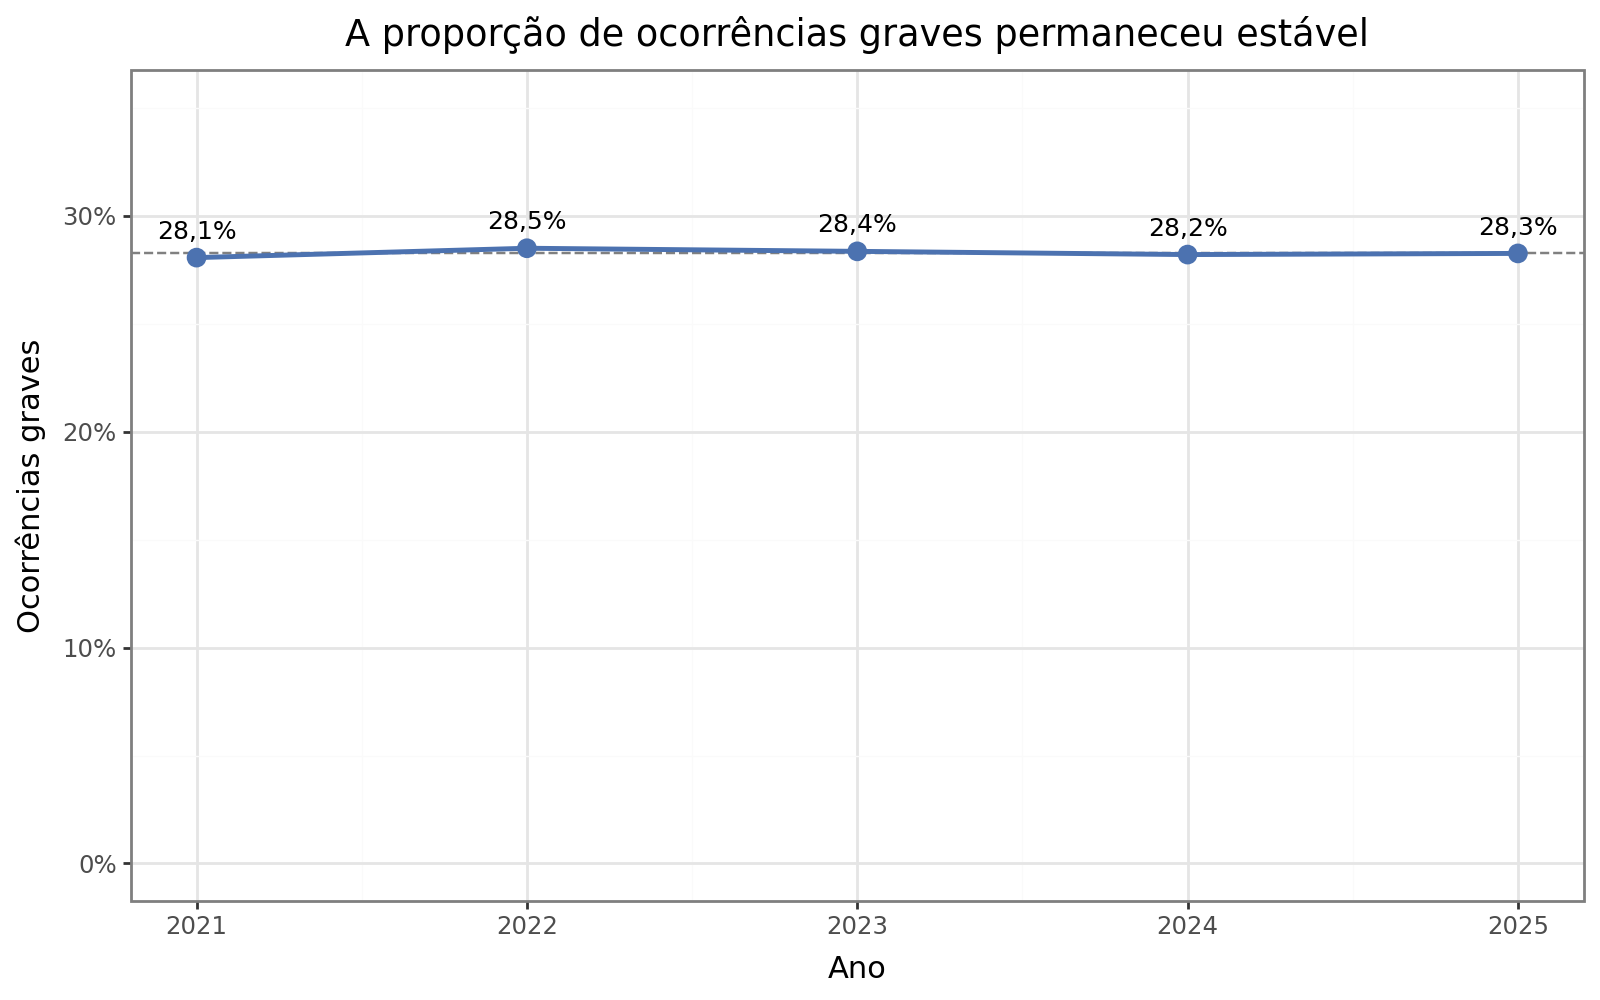

In [11]:
por_ano["rotulo"] = por_ano["prop_grave"].map("{:.1%}".format).str.replace(".", ",")

grafico_anual = (
    ggplot(por_ano, aes(x="ano", y="prop_grave", group=1))
    + geom_hline(yintercept=media_grave, linetype="dashed", color="gray")
    + geom_line(color="#4C72B0", size=1)
    + geom_point(color="#4C72B0", size=3)
    + geom_text(aes(label="rotulo"), nudge_y=0.012, size=9)
    + scale_x_continuous(breaks=range(2021, 2026))
    + scale_y_continuous(labels=percent_format(), limits=(0, 0.35))
    + labs(
        x="Ano",
        y="Ocorrências graves",
        title="A proporção de ocorrências graves permaneceu estável"
    )
    + theme(figure_size=(8, 5))
)

grafico_anual

O número de ocorrências ficou estável em 2021 e 2022 (cerca de 64,6 mil), subiu em 2023 e 2024 (73,2 mil) e permaneceu nesse patamar em 2025, um aumento de 12,3% entre 2021 e 2025. O número de mortos acompanhou esse movimento, de 5.397 para 6.043 (+12,0%). A **proporção observada** de ocorrências graves, porém, permaneceu entre 28,1% e 28,5%. Como a base não traz fluxo de veículos, o aumento das contagens não pode ser interpretado como aumento do risco de trafegar.

In [12]:
# Exploração horária retirada do corpo final para manter o relatório objetivo.

In [13]:
# Exploração por dia da semana retirada do corpo final.

In [14]:
# Gráfico por dia da semana retirado do corpo final.

In [15]:
# Tabela mensal retirada do corpo final.

Como a base não possui medidas de exposição ao tráfego, comparações entre UFs e rodovias não serão apresentadas como medidas de risco no relatório final.

In [16]:
# Análise geográfica retirada: a base não possui denominadores de exposição ao tráfego.

In [17]:
# Ranking de rodovias retirado: contagens sem exposição não representam risco de trafegar.

In [18]:
# A coerência entre classificação e vítimas já foi resumida na seção de qualidade.

### 8.3 Tipo do acidente

Para evitar proporções instáveis, são apresentados apenas tipos com pelo menos 1.000 ocorrências. O tamanho de cada grupo aparece no próprio gráfico. A causa será tratada somente no modelo ampliado, com agrupamento de categorias raras definido no treino.

In [19]:
# Gráfico separado de causas retirado; a variável será tratada no modelo ampliado.

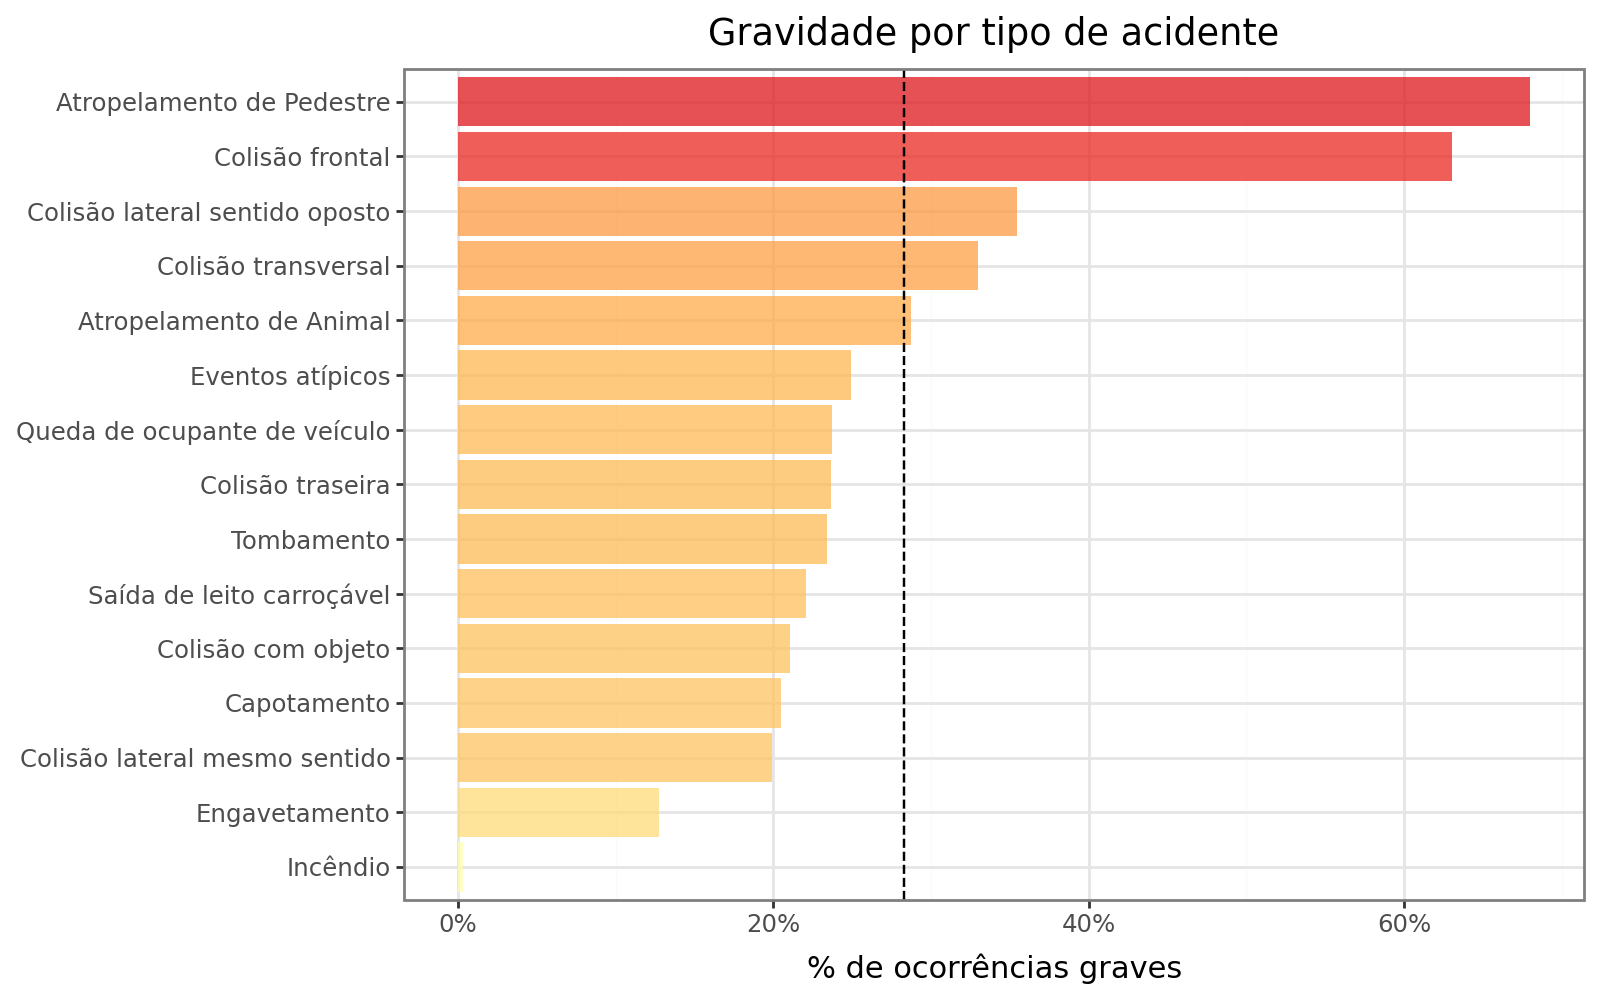

In [20]:
(base.groupby("tipo_acidente", as_index = False)
     .agg(ocorrencias = ("id", "size"), prop_grave = ("grave", "mean"))
     .query("ocorrencias >= 1000")
     .pipe(lambda _: ggplot(_, aes(x = "reorder(tipo_acidente, prop_grave)", y = "prop_grave", fill = "prop_grave")) +
                         geom_col(alpha = 0.75, show_legend = False) +
                         geom_hline(yintercept = media_grave, linetype = "dashed") +
                         scale_fill_distiller(palette = "YlOrRd", direction = 1, limits = (0, 0.8)) +
                         scale_y_continuous(labels = percent_format()) +
                         labs(x = "", y = "% de ocorrências graves", title = "Gravidade por tipo de acidente") +
                         coord_flip() +
                         theme(figure_size = (8, 5))))

Atropelamento de pedestre (68,0%) e colisão frontal (63,1%) apresentam as maiores proporções de ocorrências graves e, juntos, representam cerca de 11% das ocorrências. No extremo oposto, engavetamento (12,8%) e incêndio (0,3%) apresentam proporções menores.

O tipo é classificado depois do acidente e, portanto, será usado apenas no modelo descritivo ampliado, não como informação disponível antes da ocorrência.

### 9.3 Condições da pista, do ambiente e do veículo

Os gráficos abaixo usam o mesmo formato para quatro variáveis de contexto, o que facilita comparar a diferença entre categorias.

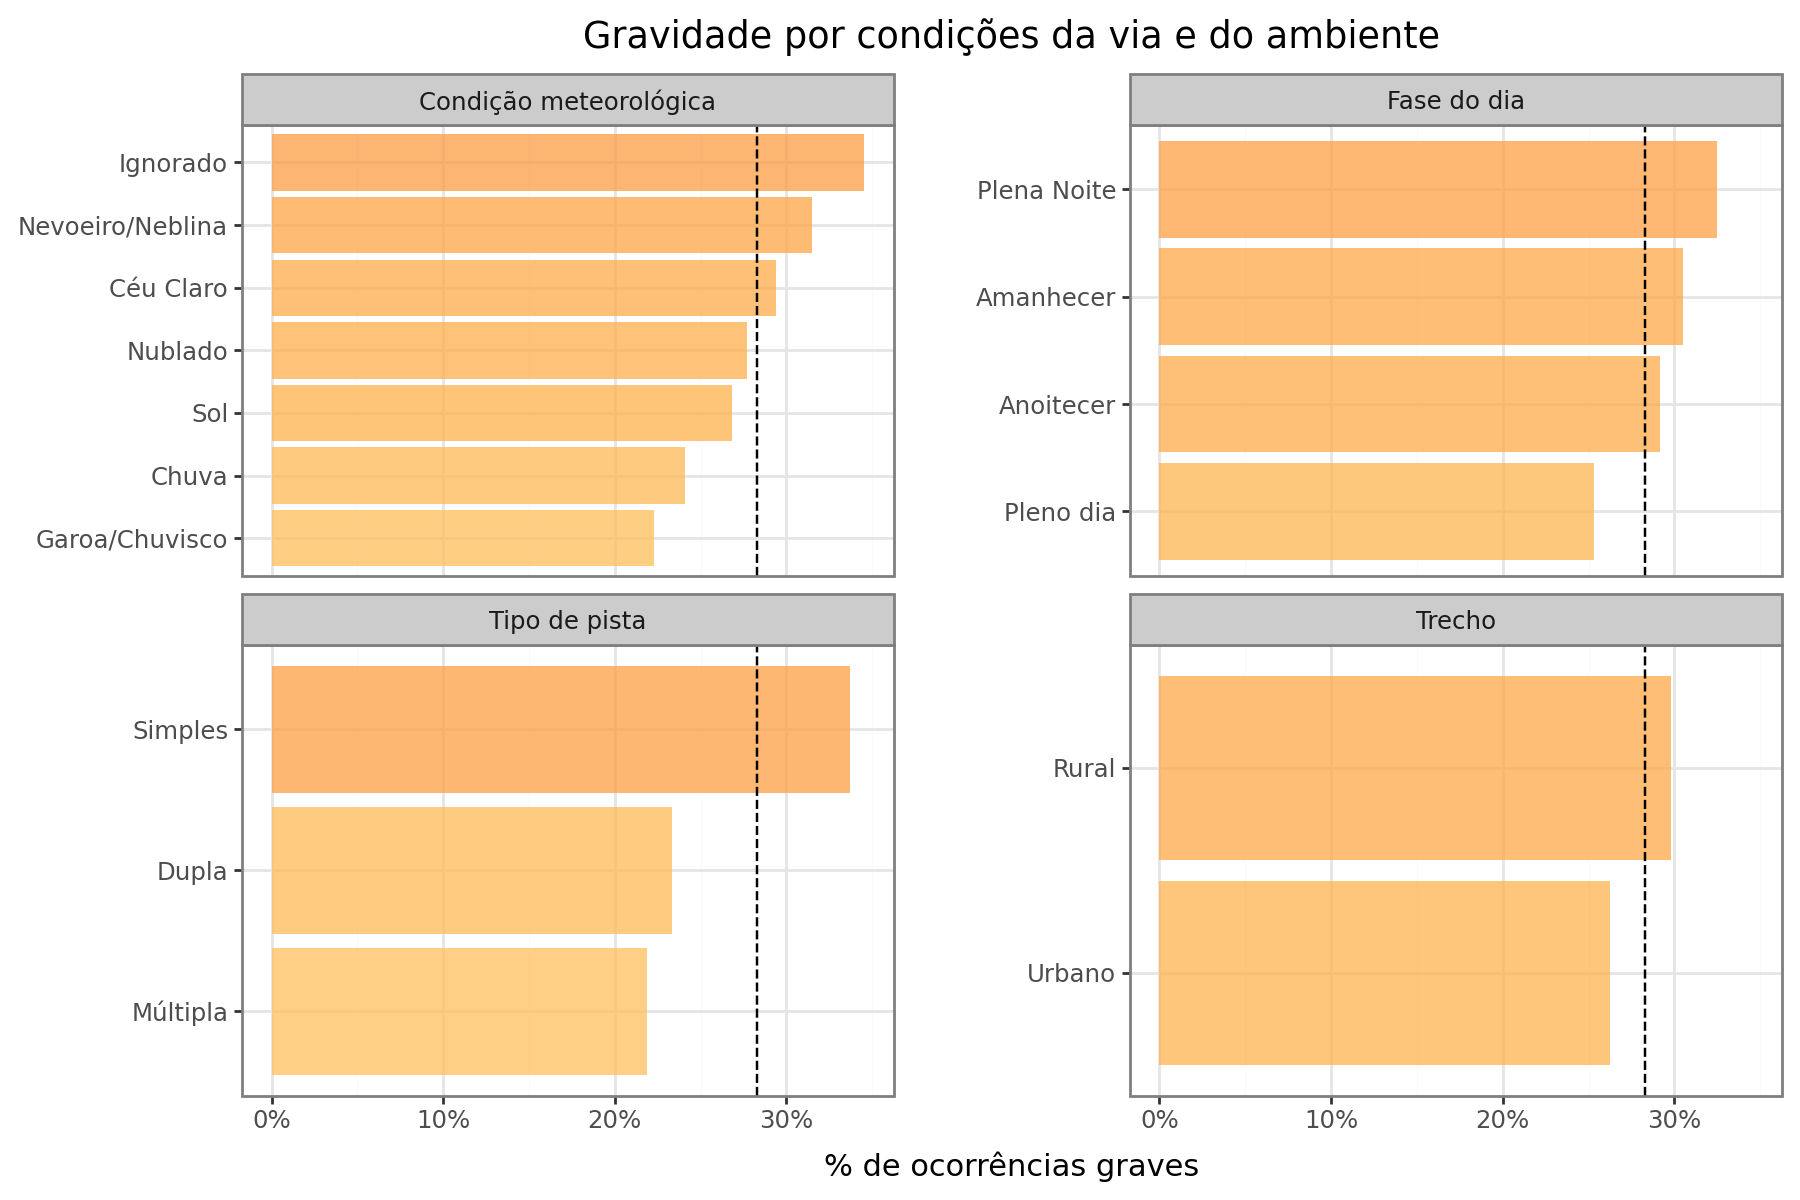

In [21]:
nomes = {"tipo_pista": "Tipo de pista", "trecho": "Trecho",
         "fase_dia": "Fase do dia", "condicao_metereologica": "Condição meteorológica"}

(base.melt(id_vars = "grave", value_vars = list(nomes), var_name = "variavel", value_name = "categoria")
     .groupby(["variavel", "categoria"], as_index = False)
     .agg(ocorrencias = ("grave", "size"), prop_grave = ("grave", "mean"))
     .query("ocorrencias >= 1000")
     .assign(variavel = lambda _: _.variavel.replace(nomes))
     .pipe(lambda _: ggplot(_, aes(x = "reorder(categoria, prop_grave)", y = "prop_grave", fill = "prop_grave")) +
                         geom_col(alpha = 0.75, show_legend = False) +
                         geom_hline(yintercept = media_grave, linetype = "dashed") +
                         scale_fill_distiller(palette = "YlOrRd", direction = 1, limits = (0, 0.8)) +
                         scale_y_continuous(labels = percent_format()) +
                         facet_wrap("variavel", scales = "free_y", ncol = 2) +
                         labs(x = "", y = "% de ocorrências graves", title = "Gravidade por condições da via e do ambiente") +
                         coord_flip() +
                         theme(figure_size = (9, 6))))

In [22]:
(base.pivot_table(index = "tipo_pista", columns = "trecho", values = "grave",
                  aggfunc = "mean", margins = True, margins_name = "Total")
     .round(3))

trecho,Rural,Urbano,Total
tipo_pista,,,
Dupla,0.227,0.240,0.234
Múltipla,0.205,0.223,0.219
Simples,0.350,0.310,0.337
Total,0.298,0.262,0.283


In [23]:
# A variável veículos será tratada diretamente no modelo ampliado.

A diferença mais clara está no **tipo de pista**: em pista simples, 33,7% das ocorrências são graves, contra 23,4% em pista dupla e 21,9% em pista múltipla. No total, trechos rurais apresentam 29,8% de ocorrências graves, contra 26,2% nos urbanos. Entretanto, a composição entre tipo de pista e trecho é diferente, e essas comparações agregadas não identificam a associação independente de nenhuma das variáveis. Por isso, elas serão analisadas em conjunto e com uma interação no modelo.

A associação com a **condição meteorológica** é menos clara. Nevoeiro/neblina apresenta 31,5% de ocorrências graves, chuva 24,1%, garoa 22,3% e céu claro 29,4%. Essas diferenças podem refletir outras características das ocorrências e serão examinadas no modelo com as demais variáveis. A categoria "Ignorado" será mantida como categoria própria.

## 9. Modelo de contexto

O primeiro modelo utiliza somente características de contexto: faixa de horário, UF, condição meteorológica, tipo de pista e trecho urbano ou rural. A variável resposta é `grave`, igual a 1 quando há pelo menos uma morte ou pessoa gravemente ferida.

As contagens de vítimas, `classificacao_acidente` e `pessoas` não entram como preditoras, pois revelam ou se relacionam diretamente com a construção do desfecho. Tipo e causa do acidente também ficam fora desta especificação e serão acrescentados posteriormente no modelo descritivo ampliado.

### 9.1 Preparação para a modelagem

As faixas de horário são: madrugada (0h–5h), manhã (6h–11h), tarde (12h–17h) e noite (18h–23h). A estimação utiliza 2021–2024 e a avaliação fora da amostra será feita com 2025.

In [24]:
import statsmodels.formula.api as smf
from scipy.stats import chi2
import numpy as np

base["faixa_horaria"] = pd.cut(
    base["hora"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Madrugada", "Manhã", "Tarde", "Noite"]
)

treino = base[base["ano"] <= 2024].copy()
teste = base[base["ano"] == 2025].copy()

variaveis_contexto = [
    "grave",
    "faixa_horaria",
    "uf",
    "condicao_metereologica",
    "tipo_pista",
    "trecho"
]

assert treino[variaveis_contexto].isna().sum().sum() == 0
assert teste[variaveis_contexto].isna().sum().sum() == 0

categorias_novas_2025 = {}

for variavel in variaveis_contexto[1:]:
    categorias_treino = set(treino[variavel].astype(str))
    categorias_teste = set(teste[variavel].astype(str))
    categorias_novas_2025[variavel] = categorias_teste - categorias_treino

assert all(len(categorias) == 0 for categorias in categorias_novas_2025.values())

base["conjunto"] = "treino (2021–2024)"
base.loc[base["ano"] == 2025, "conjunto"] = "teste (2025)"

resumo_conjuntos = base.groupby("conjunto").agg(
    ocorrencias=("id", "size"),
    graves=("grave", "sum"),
    prop_grave=("grave", "mean")
).reset_index()

resumo_conjuntos

,conjunto,ocorrencias,graves,prop_grave
0,teste (2025),72529,20493,0.282549
1,treino (2021–2024),270141,76383,0.282752


### 9.2 Modelo A: características de contexto

A regressão logística usa como referências manhã, SP, céu claro, pista dupla e trecho urbano. Assim, cada coeficiente compara uma categoria com sua referência, mantendo constantes as demais variáveis do modelo. A UF é mantida como controle, mas seus 26 coeficientes não serão mostrados na tabela compacta.

In [25]:
formula_contexto = """
grave ~ C(faixa_horaria, Treatment(reference='Manhã'))
      + C(uf, Treatment(reference='SP'))
      + C(condicao_metereologica, Treatment(reference='Céu Claro'))
      + C(tipo_pista, Treatment(reference='Dupla'))
      + C(trecho, Treatment(reference='Urbano'))
"""

modelo_contexto = smf.logit(
    formula_contexto,
    data=treino
).fit(disp=False)

assert modelo_contexto.mle_retvals["converged"]

### 9.3 Interação entre tipo de pista e trecho

Uma segunda especificação verifica se a associação entre o tipo de pista e a gravidade muda entre trechos urbanos e rurais. Ela mantém os mesmos controles do Modelo A e acrescenta a interação `tipo_pista × trecho`.

In [26]:
formula_interacao = """
grave ~ C(faixa_horaria, Treatment(reference='Manhã'))
      + C(uf, Treatment(reference='SP'))
      + C(condicao_metereologica, Treatment(reference='Céu Claro'))
      + C(tipo_pista, Treatment(reference='Dupla'))
        * C(trecho, Treatment(reference='Urbano'))
"""

modelo_interacao = smf.logit(
    formula_interacao,
    data=treino
).fit(disp=False)

assert modelo_interacao.mle_retvals["converged"]

estatistica_lr = 2 * (modelo_interacao.llf - modelo_contexto.llf)
graus_liberdade = int(modelo_interacao.df_model - modelo_contexto.df_model)
valor_p_lr = chi2.sf(estatistica_lr, graus_liberdade)

comparacao_modelos = pd.DataFrame({
    "modelo": ["Contexto", "Contexto + interação"],
    "AIC": [modelo_contexto.aic, modelo_interacao.aic],
    "log_verossimilhanca": [modelo_contexto.llf, modelo_interacao.llf],
    "estatistica_LR": [np.nan, estatistica_lr],
    "graus_liberdade": [np.nan, graus_liberdade],
    "valor_p_LR": [np.nan, valor_p_lr]
})

comparacao_modelos.round(3)

,modelo,AIC,log_verossimilhanca,estatistica_LR,graus_liberdade,valor_p_LR
0,Contexto,312333.156,-156124.578,NaN,NaN,NaN
1,Contexto + interação,312209.032,-156060.516,128.124,2.0,0.0


O modelo com interação apresenta AIC menor. O teste de razão de verossimilhanças compara formalmente as duas especificações; um valor-p pequeno indica que a interação acrescenta informação ao modelo de contexto. Por isso, a versão com interação será usada na interpretação e entregue para a avaliação em 2025.

### 9.4 *Odds ratios* e interpretação

Os coeficientes da regressão foram transformados em razões de chances (*odds ratios*, OR). Valores acima de 1 indicam chances relativas maiores que a categoria de referência; valores abaixo de 1 indicam chances relativas menores. Essas relações são associações condicionais, não efeitos causais.

In [27]:
intervalos = modelo_interacao.conf_int()

tabela_or = pd.DataFrame({
    "termo": modelo_interacao.params.index,
    "OR": np.exp(modelo_interacao.params.values),
    "IC_95_inferior": np.exp(intervalos[0].values),
    "IC_95_superior": np.exp(intervalos[1].values),
    "valor_p": modelo_interacao.pvalues.values
})

tabela_or = tabela_or[tabela_or["termo"] != "Intercept"]
tabela_or = tabela_or[~tabela_or["termo"].str.contains("C(uf", regex=False)]

nomes_termos = {
    "C(faixa_horaria, Treatment(reference='Manhã'))[T.Madrugada]": "Horário: Madrugada",
    "C(faixa_horaria, Treatment(reference='Manhã'))[T.Tarde]": "Horário: Tarde",
    "C(faixa_horaria, Treatment(reference='Manhã'))[T.Noite]": "Horário: Noite",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Chuva]": "Clima: Chuva",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Garoa/Chuvisco]": "Clima: Garoa/Chuvisco",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Granizo]": "Clima: Granizo",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Ignorado]": "Clima: Ignorado",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Neve]": "Clima: Neve",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Nevoeiro/Neblina]": "Clima: Nevoeiro/Neblina",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Nublado]": "Clima: Nublado",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Sol]": "Clima: Sol",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Vento]": "Clima: Vento",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Múltipla]": "Pista: Múltipla",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Simples]": "Pista: Simples",
    "C(trecho, Treatment(reference='Urbano'))[T.Rural]": "Trecho: Rural",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Múltipla]:C(trecho, Treatment(reference='Urbano'))[T.Rural]": "Interação: Múltipla × Rural",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Simples]:C(trecho, Treatment(reference='Urbano'))[T.Rural]": "Interação: Simples × Rural"
}

tabela_or["termo"] = tabela_or["termo"].replace(nomes_termos)
tabela_or.round({
    "OR": 2,
    "IC_95_inferior": 2,
    "IC_95_superior": 2,
    "valor_p": 3
})

,termo,OR,IC_95_inferior,IC_95_superior,valor_p
1,Horário: Madrugada,1.34,1.30,1.38,0.000
2,Horário: Tarde,1.07,1.05,1.10,0.000
3,Horário: Noite,1.47,1.43,1.50,0.000
30,Clima: Chuva,0.80,0.77,0.82,0.000
31,Clima: Garoa/Chuvisco,0.71,0.68,0.75,0.000
32,Clima: Granizo,0.27,0.03,2.12,0.213
33,Clima: Ignorado,1.10,1.03,1.19,0.007
34,Clima: Neve,0.31,0.04,2.64,0.285
35,Clima: Nevoeiro/Neblina,1.09,0.99,1.19,0.077
36,Clima: Nublado,0.95,0.93,0.98,0.000


Mantidas constantes UF, clima, pista e trecho, ocorrências noturnas apresentam chances relativas de gravidade aproximadamente **47% maiores** que as da manhã; na madrugada, a diferença é de cerca de **34%**, e à tarde, de **7%**.

A interação modifica a leitura das pistas. Em trecho urbano, pista simples apresenta OR de aproximadamente **1,38** em relação à pista dupla. Em trecho rural, essa comparação recebe ainda o multiplicador da interação, próximo de **1,24**; combinados, os termos indicam OR de aproximadamente **1,71** para pista simples contra dupla no meio rural. Esses resultados descrevem associações nos acidentes registrados e não demonstram que o tipo de pista ou o trecho cause a gravidade.

Categorias meteorológicas com poucos registros, como neve e granizo, devem ser interpretadas com cautela, mesmo quando aparecem na tabela.

### 9.5 Objetos preparados para a avaliação

As probabilidades dos dois modelos são calculadas para 2025. Elas serão usadas posteriormente para AUC-ROC, PR-AUC, precisão e revocação, junto ao Modelo B.

In [28]:
teste["prob_contexto"] = modelo_contexto.predict(teste)
teste["prob_contexto_interacao"] = modelo_interacao.predict(teste)

assert teste["prob_contexto"].between(0, 1).all()
assert teste["prob_contexto_interacao"].between(0, 1).all()

teste[["prob_contexto", "prob_contexto_interacao"]].describe().round(3)

,prob_contexto,prob_contexto_interacao
count,72529.000,72529.000
mean,0.283,0.283
std,0.085,0.086
min,0.111,0.113
25%,0.218,0.216
50%,0.275,0.276
75%,0.337,0.337
max,0.573,0.580


## 10. Síntese parcial

### 10.1 Principais achados

1. **Nível e tendência.** O número de ocorrências cresceu 12,3% entre 2021 e 2025, mas a proporção de graves permaneceu próxima de 28,3%.
2. **Tipo do acidente.** Atropelamentos de pedestre (68,0%) e colisões frontais (63,1%) apresentam as maiores proporções observadas de ocorrências graves.
3. **Modelo de contexto.** Horário, UF, clima, tipo de pista e trecho apresentam associações com a gravidade. A interação mostra que a comparação entre os tipos de pista muda entre trechos urbanos e rurais.
4. **Qualidade.** Em 18.541 ocorrências, a soma dos estados físicos supera `pessoas`. Os registros foram preservados e `pessoas` não foi usada no modelo.

### 10.2 Limitações

- A base cobre apenas acidentes registrados pela PRF em rodovias federais, e não permite generalizar para o trânsito brasileiro como um todo.
- Sem dados de exposição, as comparações não medem o risco de trafegar em uma UF, rodovia ou condição específica.
- Os resultados são associações, não efeitos causais; variáveis omitidas podem explicar parte dos padrões.
- Causa e tipo do acidente são classificações feitas após a ocorrência e podem conter erro ou subjetividade.
- Algumas categorias meteorológicas possuem poucos registros e estimativas menos precisas.

### 10.3 Etapas pendentes

1. Agrupar causas raras usando somente o treino de 2021–2024.
2. Ajustar o Modelo B com tipo, causa e número de veículos.
3. Calcular AUC-ROC, PR-AUC, precisão e revocação em 2025 para comparar os modelos.
4. Substituir esta síntese parcial pela conclusão definitiva.

## Referências

IPEA; POLÍCIA RODOVIÁRIA FEDERAL. **Acidentes de trânsito nas rodovias federais brasileiras: caracterização, tendências e custos para a sociedade**. Brasília: Ipea, 2015. (Relatório de Pesquisa).

ORGANIZAÇÃO DAS NAÇÕES UNIDAS. **Resolução A/RES/74/299: Melhorando a segurança no trânsito global**. Nova York: Assembleia Geral, 2020.

POLÍCIA RODOVIÁRIA FEDERAL. **Dados Abertos da PRF**. Disponível em: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf>. Acesso em: 19 out. 2026.

POLÍCIA RODOVIÁRIA FEDERAL. **Dicionário de dados - Acidentes**. Disponível em: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes>. Acesso em: 19 out. 2026.